In [10]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

possible_paths = [
    Path("data/processed/ChargingRecords_cleaned.csv"),
    Path("ChargingRecords_cleaned.csv"),
    Path("../data/processed/ChargingRecords_cleaned.csv")
]

DATA_PATH = next((p for p in possible_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "ChargingRecords_cleaned.csv not found. "
        "Check your data/processed folder."
    )

df = pd.read_csv(DATA_PATH)

for col in ["StartDatetime", "EndDatetime"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

df["Demand"] = pd.to_numeric(df["Demand"], errors="coerce")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (72799, 13)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:02,2022-09-15 23:59:13,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:05,2022-09-14 21:31:04,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:30,2022-09-14 19:54:29,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:51,2022-09-30 00:16:42,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:15,2022-09-26 00:30:14,300,33.81


In [11]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDataset information:")
df.info()

Number of rows: 72799
Number of columns: 13

Column names:
['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand']

Data types:


,Data Type
UserID,int64
ChargerID,int64
ChargerCompany,int64
Location,str
ChargerType,int64
StartDay,str
StartTime,str
EndDay,str
EndTime,str
StartDatetime,datetime64[us]



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 72799 entries, 0 to 72798
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   UserID          72799 non-null  int64         
 1   ChargerID       72799 non-null  int64         
 2   ChargerCompany  72799 non-null  int64         
 3   Location        72799 non-null  str           
 4   ChargerType     72799 non-null  int64         
 5   StartDay        72799 non-null  str           
 6   StartTime       72799 non-null  str           
 7   EndDay          72799 non-null  str           
 8   EndTime         72799 non-null  str           
 9   StartDatetime   72799 non-null  datetime64[us]
 10  EndDatetime     72799 non-null  datetime64[us]
 11  Duration        72799 non-null  int64         
 12  Demand          72799 non-null  float64       
dtypes: datetime64[us](2), float64(1), int64(5), str(5)
memory usage: 10.3 MB


In [12]:
missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

print("Missing values:")
display(missing_report)

print("Duplicate rows:", df.duplicated().sum())

Missing values:


,Missing_Count,Missing_Percentage
UserID,0,0.0
ChargerID,0,0.0
ChargerCompany,0,0.0
Location,0,0.0
ChargerType,0,0.0
StartDay,0,0.0
StartTime,0,0.0
EndDay,0,0.0
EndTime,0,0.0
StartDatetime,0,0.0


Duplicate rows: 0


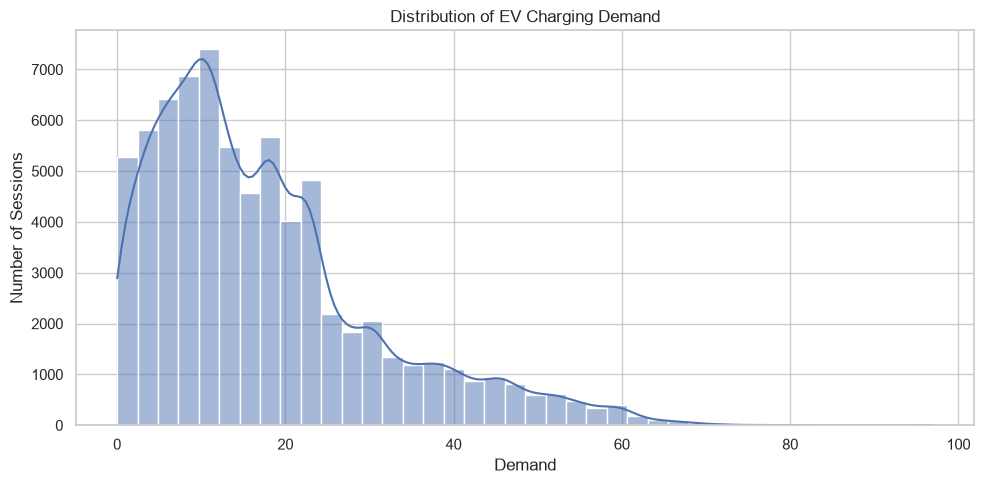

Demand statistics:


count    72799.000000
mean        17.444245
std         13.490308
min          0.010000
25%          7.540000
50%         14.100000
75%         23.200000
max         97.000000
Name: Demand, dtype: float64

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Demand",
    bins=40,
    kde=True
)

plt.title("Distribution of EV Charging Demand")
plt.xlabel("Demand")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()

print("Demand statistics:")
display(df["Demand"].describe())

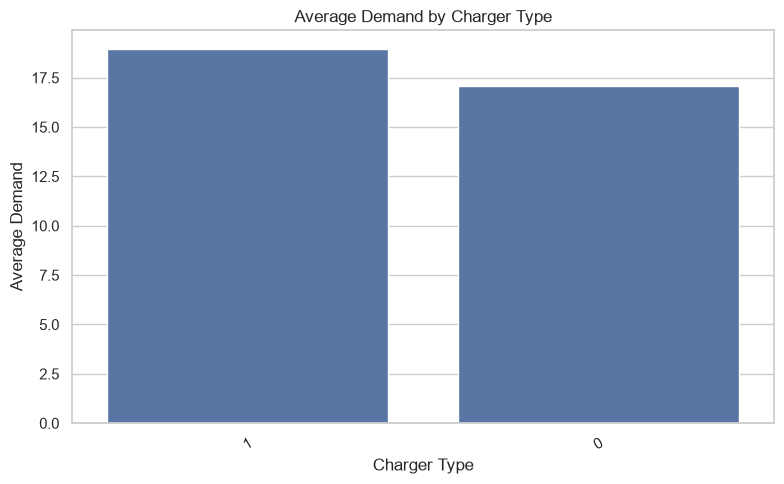

,Average_Demand
ChargerType,
1,18.946402
0,17.056694


In [14]:
if "ChargerType" in df.columns:
    charger_demand = (
        df.groupby("ChargerType", dropna=False)["Demand"]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(8, 5))
    sns.barplot(
        x=charger_demand.index.astype(str),
        y=charger_demand.values
    )

    plt.title("Average Demand by Charger Type")
    plt.xlabel("Charger Type")
    plt.ylabel("Average Demand")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

    display(charger_demand.to_frame("Average_Demand"))
else:
    print("ChargerType column not found.")

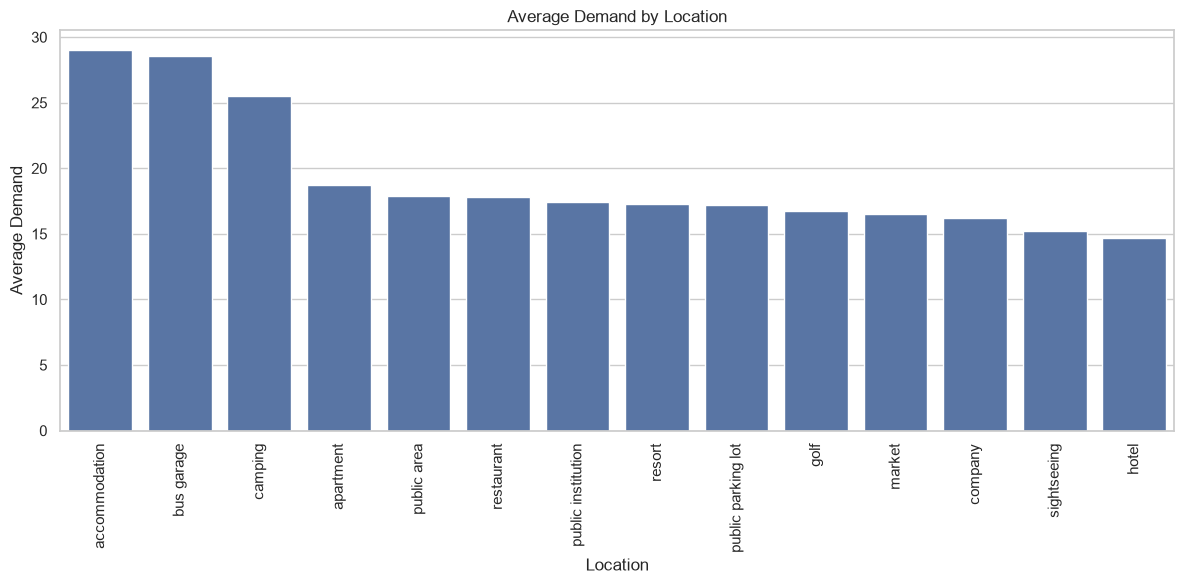

,Average_Demand
Location,
accommodation,29.055829
bus garage,28.587586
camping,25.525288
apartment,18.750339
public area,17.898904
restaurant,17.813123
public institution,17.399318
resort,17.290365
public parking lot,17.187510


In [15]:
if "Location" in df.columns:
    location_demand = (
        df.groupby("Location", dropna=False)["Demand"]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=location_demand.index.astype(str),
        y=location_demand.values
    )

    plt.title("Average Demand by Location")
    plt.xlabel("Location")
    plt.ylabel("Average Demand")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

    display(location_demand.to_frame("Average_Demand"))
else:
    print("Location column not found.")

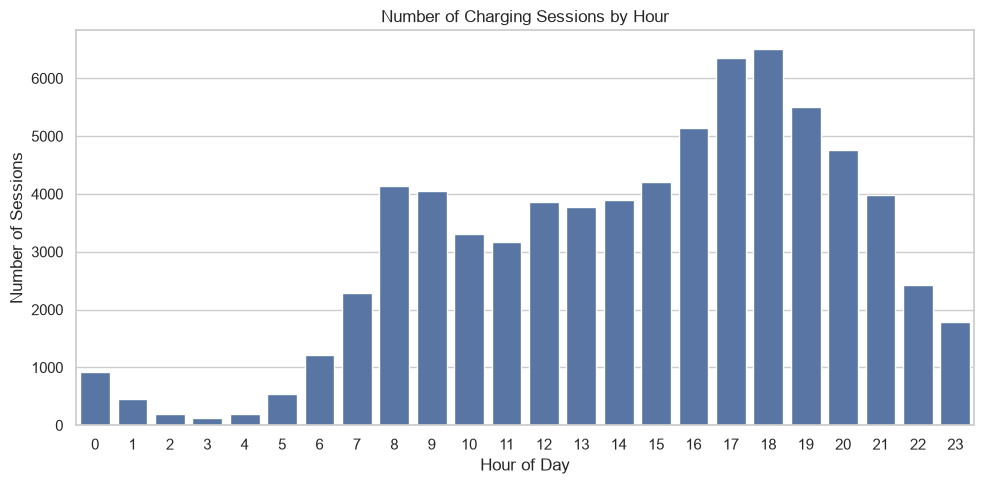

,Session_Count
StartHour,
0,919
1,449
2,200
3,134
4,190
5,549
6,1214
7,2291
8,4142


In [16]:
if "StartDatetime" in df.columns:
    df["StartHour"] = df["StartDatetime"].dt.hour

    hourly_sessions = (
        df.groupby("StartHour")
        .size()
        .reindex(range(24), fill_value=0)
    )

    plt.figure(figsize=(10, 5))
    sns.barplot(
        x=hourly_sessions.index,
        y=hourly_sessions.values
    )

    plt.title("Number of Charging Sessions by Hour")
    plt.xlabel("Hour of Day")
    plt.ylabel("Number of Sessions")
    plt.xticks(range(24))
    plt.tight_layout()
    plt.show()

    display(hourly_sessions.to_frame("Session_Count"))
else:
    print("StartDatetime column not found.")

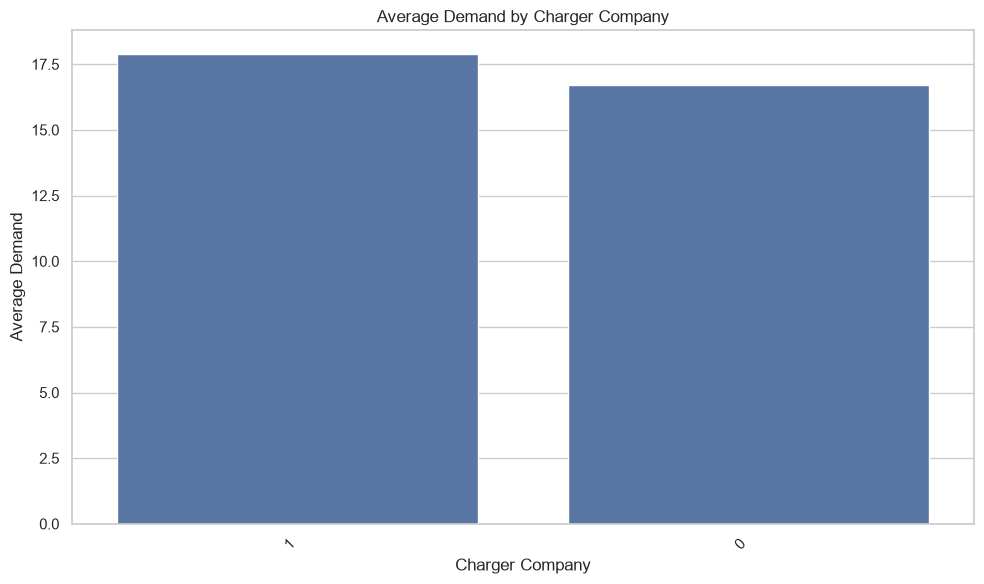

,Average_Demand
ChargerCompany,
1,17.890933
0,16.691300


In [17]:
if "ChargerCompany" in df.columns:
    company_demand = (
        df.groupby("ChargerCompany", dropna=False)["Demand"]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 6))
    sns.barplot(
        x=company_demand.index.astype(str),
        y=company_demand.values
    )

    plt.title("Average Demand by Charger Company")
    plt.xlabel("Charger Company")
    plt.ylabel("Average Demand")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    display(company_demand.to_frame("Average_Demand"))
else:
    print("ChargerCompany column not found.")

In [18]:
OUTPUT_DIR = Path("reports")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# General dataset summary
df.describe(include="all").T.to_csv(
    OUTPUT_DIR / "eda_summary.csv"
)

# Missing values report
missing_report.to_csv(
    OUTPUT_DIR / "missing_values_report.csv"
)

# Average demand by location
if "Location" in df.columns:
    location_demand = (
        df.groupby("Location", as_index=False)["Demand"]
        .mean()
        .rename(columns={"Demand": "Average_Demand"})
    )

    location_demand.to_csv(
        OUTPUT_DIR / "demand_by_location.csv",
        index=False
    )

# Average demand by charger type
if "ChargerType" in df.columns:
    charger_demand_report = (
        df.groupby("ChargerType", as_index=False)["Demand"]
        .mean()
        .rename(columns={"Demand": "Average_Demand"})
    )

    charger_demand_report.to_csv(
        OUTPUT_DIR / "demand_by_charger_type.csv",
        index=False
    )

# Average demand by charger company
if "ChargerCompany" in df.columns:
    company_demand_report = (
        df.groupby("ChargerCompany", as_index=False)["Demand"]
        .mean()
        .rename(columns={"Demand": "Average_Demand"})
    )

    company_demand_report.to_csv(
        OUTPUT_DIR / "demand_by_company.csv",
        index=False
    )

print("EDA completed successfully!")
print("Reports saved to:", OUTPUT_DIR.resolve())

EDA completed successfully!
Reports saved to: C:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis\notebook\reports
